# Etapa 03: Qué vale la pena modelar a fondo y cuántas muestras van a llegar

Este notebook tiene dos partes. Con la base del laboratorio se pueden plantear muchos análisis (prever volúmenes,
anticipar resultados, agrupar clientes) y no nos daba el tiempo para estudiarlos todos a fondo. Así que en la parte A
los pasamos a todos por la misma prueba rápida y decidimos con una regla, escrita antes de ver resultados, cuáles
pasan al modelado a fondo. En la parte B modelamos a fondo el análisis de regresión elegido, que prevé la carga de
trabajo del laboratorio. La clasificación y el agrupamiento elegidos siguen en las etapas 04 y 05.

← Anterior: [Etapa 02: Base real](02_base_real.ipynb)<br>[Notebook completo](Proyecto_Final.ipynb)<br>Siguiente: [Etapa 04: Clasificación y Bayes](04_clasificacion_bayes.ipynb) →

## Código del proyecto

La celda siguiente prepara el código del proyecto. En una copia del repositorio no hace nada y en Google Colab trae el paquete `proyecto/` desde `notebooks/codigo/` (si se subió junto al notebook) o desde el repositorio, así que basta con ejecutar todo (*Entorno de ejecución → Ejecutar todas*). La sección se puede plegar desde su título. Trae también los guiones de las etapas anteriores: Si sus resultados no están en la sesión, la etapa los vuelve a calcular en silencio antes de empezar.

In [ ]:
# Código del proyecto (69 archivos, 221 kB): el paquete proyecto/ (56 módulos) y el mapeo de columnas, los guiones de las 2 etapas previas.
# En una copia del repositorio o en la carpeta de la entrega ya está y no se toca nada.
# En Colab se extrae de codigo/03_cribado_regresion.tar.xz si se subió junto al notebook o se descarga
# del repositorio; en los dos casos se comprueba su huella SHA-256 antes de extraerlo.
# Un archivo local con otro contenido se conserva (SOBRESCRIBIR = True lo reemplaza).
import hashlib, importlib, io, os, sys, tarfile, urllib.request
from pathlib import Path

ARCHIVO, HUELLA, SOBRESCRIBIR = "03_cribado_regresion.tar.xz", "35154104735048a332d7bb32d11d0bb4a1a21fb89c9ad3277256af1bc9bbb3ad", False
URL = "https://raw.githubusercontent.com/Over-HCV/ML-I/main/content/docs/final-project/notebooks/codigo/" + ARCHIVO

if Path.cwd().name == "notebooks" and Path("../proyecto/__init__.py").exists():
    os.chdir("..")  # abierto desde notebooks/: se trabaja en la raíz del proyecto


def recrear_proyecto():
    origen = next((Path(d) / ARCHIVO for d in ("notebooks/codigo", "codigo", ".") if (Path(d) / ARCHIVO).exists()), None)
    if origen is None and Path("proyecto/__init__.py").exists():
        escritos, iguales, conservados = 0, None, []
    else:
        datos = origen.read_bytes() if origen else urllib.request.urlopen(URL, timeout=60).read()
        if hashlib.sha256(datos).hexdigest() != HUELLA:
            raise ValueError(f"{ARCHIVO} no corresponde a este notebook: su SHA-256 no coincide.")
        escritos, iguales, conservados = 0, 0, []
        with tarfile.open(fileobj=io.BytesIO(datos), mode="r:xz") as archivo:
            for miembro in archivo.getmembers():
                destino = Path(miembro.name)
                if destino.is_absolute() or ".." in destino.parts:
                    raise ValueError(f"Ruta no permitida en el archivo: {miembro.name}")
                contenido = archivo.extractfile(miembro).read()
                if destino.exists() and destino.read_bytes() == contenido:
                    iguales += 1
                elif destino.exists() and not SOBRESCRIBIR:
                    conservados.append(miembro.name)
                else:
                    destino.parent.mkdir(parents=True, exist_ok=True)
                    destino.write_bytes(contenido)
                    escritos += 1
    if os.getcwd() not in sys.path:
        sys.path.insert(0, os.getcwd())
    importlib.invalidate_caches()
    print("Código del proyecto:", "se usa la copia local." if iguales is None
          else f"{escritos} archivos escritos, {iguales} ya estaban iguales.")
    if conservados:
        print(f"Se conservaron {len(conservados)} archivos locales distintos:", ", ".join(conservados))


recrear_proyecto()

## Desarrollo de la etapa

In [1]:
from proyecto.base.artefactos import iniciar_etapa
from proyecto.base.salida import mostrar
from proyecto.etapas import cribado

iniciar_etapa("03_cribado_regresion")
c = cribado.iniciar()
mostrar(c.encabezado)

## Parte A: Cribado de análisis

## 1. El embudo de cribado

La idea la tomamos del diseño de experimentos: Probar de forma barata y pareja muchas opciones y dejar el estudio
costoso solo para las que pasan el filtro. Los cuatro pasos los escribimos antes de ver resultados:

a. **Catálogo.** Cada candidato es una ficha con su unidad, su objetivo, el momento en que predice, su métrica,
   su línea base, la decisión del laboratorio que apoya y un valor de negocio de 1 a 3 que le pusimos nosotros.
b. **Prueba rápida.** Modelos sin afinar, entrenados solo con el entrenamiento y validados con los bloques de
   ventana creciente de la etapa 01.
c. **Regla de selección.** Unos umbrales fijos deciden quién es elegible y un puntaje decide quién gana en cada
   tipo.
d. **Modelado a fondo.** Solo los ganadores pasan a la parte B (regresión) y a las etapas 04 y 05.

Para comparar candidatos tan distintos necesitábamos una sola escala, que llamamos **habilidad**: Qué parte del
camino entre la línea base y la perfección recorre el modelo. En regresión es la fracción del error de la
referencia que el modelo elimina (cero si empata con la referencia, uno si no se equivoca nunca) y en
clasificación es el coeficiente de Gini, que sale del área bajo la curva ROC (AUC, la probabilidad de que el
modelo le dé más riesgo a una no conforme que a una conforme tomadas al azar):

$$\text{habilidad}_{\text{regresión}} = 1 - \frac{{\color{#B8423F}{\mathrm{RMSE}_{\text{modelo}}}}}{{\color{#3B64A8}{\mathrm{RMSE}_{\text{referencia}}}}}
\qquad\qquad
\text{habilidad}_{\text{clasificación}} = 2\,{\color{#2F8A4E}{\mathrm{AUC}}} - 1$$

El RMSE es la raíz del error cuadrático medio, o sea el tamaño típico del error en las unidades del objetivo. En
las series de tiempo la referencia es un pronóstico ingenuo (el promedio de los últimos periodos) porque ganarle a
la media global sería demasiado fácil. El puntaje multiplica la habilidad por el valor de negocio
${\color{#C46A2B}{v}}$, de modo que un análisis muy útil para el laboratorio puede ganar con algo menos de
habilidad:

$$\text{puntaje} = \frac{\text{habilidad}\;{\color{#C46A2B}{v}}}{3}$$

Las fichas de tipo Bayes no entrenan modelos sino que aplican el teorema de Bayes a los controles de calidad, así
que no se criban y pasan directo a la etapa 04.

In [2]:
cribado.catalogo_y_regla(c).mostrar()

Análisis,Título,Unidad,Objetivo,Momento,Métrica,Línea base,Decisión que apoya,Valor
volumen_semanal_linea,Volumen semanal de muestras por línea,semana × línea de negocio,muestras_semana,programacion,rmse,base_media_4,"Programar analistas, medios de cultivo e incubadoras de la semana siguiente.",3
carga_diaria,Carga diaria del laboratorio,día hábil,muestras_dia,programacion,rmse,base_media_5,Ajustar los turnos de recepción y siembra del día siguiente.,2
dias_entrega_recepcion,Días de entrega del informe,muestra aceptada,dias_entrega,recepcion,rmse,Dummy,Prometer al cliente una fecha de entrega realista al recibir la muestra.,2
recuento_log_recepcion,Recuento microbiano (log UFC),muestra aceptada con recuento,recuento_log,recepcion,rmse,Dummy,Anticipar las diluciones necesarias antes de sembrar.,1
visitas_mensuales_cliente,Visitas de muestreo por cliente y mes,cliente × mes,visitas_mes,maestro,rmse,base_media_3,Reservar técnicos de muestreo en planta para el mes siguiente.,1
Análisis,Título,Unidad,Objetivo,Momento,Métrica,Línea base,Decisión que apoya,Valor
no_conforme_recepcion,"Resultado no conforme, visto desde la recepción",muestra aceptada,no_conforme,recepcion,roc_auc,Dummy,Priorizar la siembra y avisar pronto al cliente de las muestras de mayor riesgo.,3
falso_positivo_lectura,Falso positivo entre los no conformes,resultado no conforme reensayado,falso_positivo,lectura,roc_auc,Dummy,Decidir qué resultados no conformes conviene reensayar antes de informar.,3
entrega_tardia_recepcion,Entrega tardía del informe,muestra aceptada,entrega_tardia,recepcion,roc_auc,Dummy,Reordenar la cola o avisar al cliente cuando el plazo prometido está en riesgo.,2
cliente_inactivo_trimestre,Cliente inactivo en el trimestre siguiente,cliente × trimestre,inactivo,maestro,roc_auc,Dummy,Indicar al área comercial qué clientes contactar antes de que dejen de enviar.,2


Análisis,Tipo,Unidad,Métrica,Línea base
volumen_semanal_linea,regresion,semana × línea de negocio,rmse,base_media_4
carga_diaria,regresion,día hábil,rmse,base_media_5
dias_entrega_recepcion,regresion,muestra aceptada,rmse,Dummy
recuento_log_recepcion,regresion,muestra aceptada con recuento,rmse,Dummy
visitas_mensuales_cliente,regresion,cliente × mes,rmse,base_media_3
no_conforme_recepcion,clasificacion,muestra aceptada,roc_auc,Dummy
falso_positivo_lectura,clasificacion,resultado no conforme reensayado,roc_auc,Dummy
entrega_tardia_recepcion,clasificacion,muestra aceptada,roc_auc,Dummy
cliente_inactivo_trimestre,clasificacion,cliente × trimestre,roc_auc,Dummy
rechazo_llegada,clasificacion,muestra recibida,roc_auc,Dummy


## 2. Tablas de modelado y auditoría de fugas

Cada ficha arma su tabla a partir de las tablas limpias, con una fila por unidad de análisis (un día, una
muestra, un cliente), la fecha, el objetivo y las variables. La auditoría revisa que cada variable se conozca
antes o en el momento de la predicción y que ningún identificador ni objetivo entre como variable. Después
partimos cada tabla por fecha y la guardamos en dos archivos (desarrollo y prueba) junto con un JSON que dice el
papel de cada columna. El bloque de prueba se guarda sin abrirlo y solo la etapa 06 puede leerlo.

In [3]:
cribado.tablas_modelado(c).mostrar()

Análisis,Tipo,Unidad,Momento,Variables,Filas de desarrollo,Filas de prueba,Hallazgos de fuga,Auditoría
volumen_semanal_linea,regresion,semana × línea de negocio,programacion,19,745,215,0,superada
carga_diaria,regresion,día hábil,programacion,16,714,203,0,superada
dias_entrega_recepcion,regresion,muestra aceptada,recepcion,46,28978,8652,0,superada
recuento_log_recepcion,regresion,muestra aceptada con recuento,recepcion,50,21573,6427,0,superada
visitas_mensuales_cliente,regresion,cliente × mes,maestro,21,2059,751,0,superada
no_conforme_recepcion,clasificacion,muestra aceptada,recepcion,51,29012,8657,0,superada
falso_positivo_lectura,clasificacion,resultado no conforme reensayado,lectura,56,2179,698,0,superada
entrega_tardia_recepcion,clasificacion,muestra aceptada,recepcion,46,28978,8652,0,superada
cliente_inactivo_trimestre,clasificacion,cliente × trimestre,maestro,23,1519,480,0,superada
rechazo_llegada,clasificacion,muestra recibida,llegada,46,29899,8947,0,superada


## 3. La prueba rápida

A cada candidato supervisado lo probamos con su línea base, un modelo lineal o logístico y un árbol poco profundo
sobre el grupo ampliado de variables. A cada candidato de agrupamiento, con el estadístico de Hopkins y la mejor
silueta de K-means (las dos se explican en la sección 5). Todo con las filas del entrenamiento.

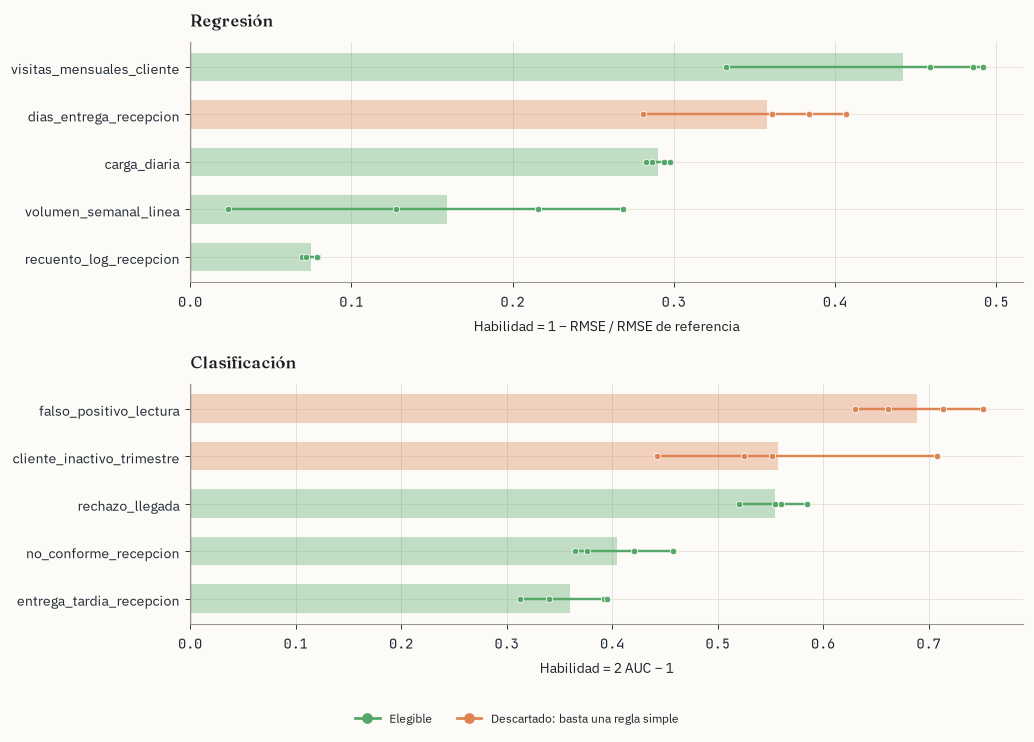

In [4]:
cribado.prueba_rapida(c).mostrar()

## 4. ¿Basta una regla simple?

Un modelo solo se justifica si combina información. Para comprobarlo entrenamos en cada bloque un árbol que ve una
sola variable (la que más aporta) y, si su habilidad llega al umbral frente al mejor modelo rápido, lo que
recomendaríamos es una regla operativa y no un modelo.

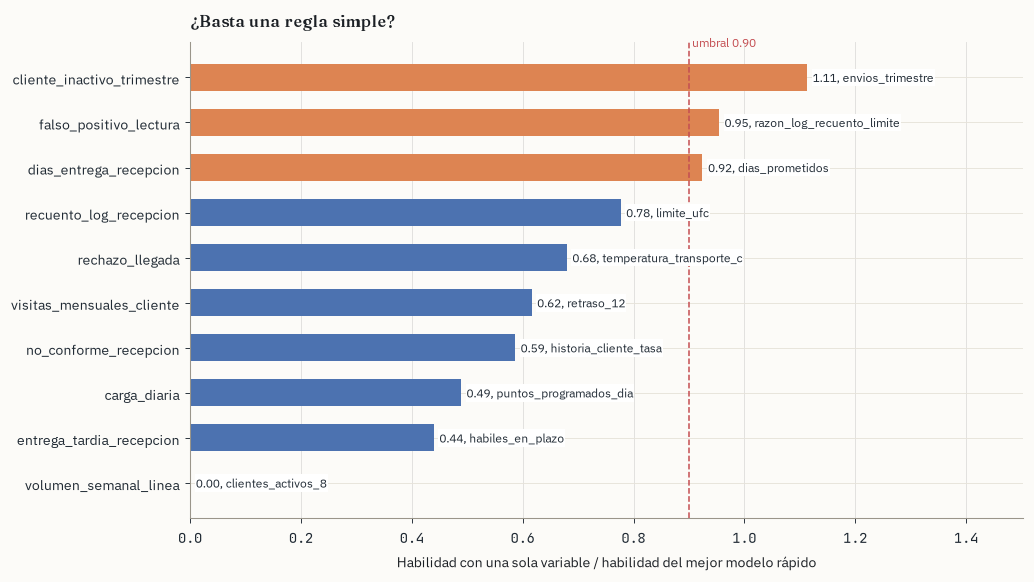

In [5]:
cribado.regla_simple(c).mostrar()

## 5. Candidatos de agrupamiento

Aquí no hay línea base que superar así que la prueba hace dos preguntas. La primera es si los datos tienden a
formar grupos, y la responde el estadístico de **Hopkins**: Compara qué tan cerca quedan los puntos reales de sus
vecinos frente a puntos puestos al azar y da cerca de 0.5 cuando no hay grupos y se acerca a uno cuando sí. La
segunda es qué tan separados quedan los grupos de K-means y la responde la **silueta**, que va de menos uno a uno
y es alta cuando cada punto está más cerca de los de su grupo que de los del grupo vecino.

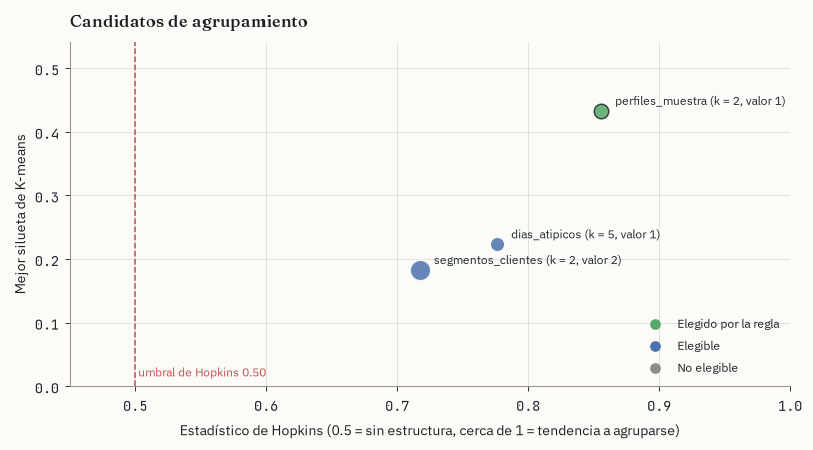

In [6]:
cribado.candidatos_agrupamiento(c).mostrar()

## 6. Selección

El embudo resume cuántos candidatos quedan en cada paso. Las comparaciones muestran los mejores puntajes de cada
tipo, incluidos los no elegibles, para que se vea qué dejamos de lado y por qué.

In [7]:
cribado.seleccion(c).mostrar()

Para ver con qué llega el clasificador elegido a la etapa 04 le preguntamos a su tabla qué momento declara, qué
variables usa y si la auditoría de fugas encontró algo:

In [8]:
from proyecto.reporte.html import fichas
from proyecto.variables.comunes import auditar_momentos

tabla, papeles = c.tablas_modelado[c.seleccion["clasificacion"]]
hallazgos = auditar_momentos(tabla, papeles)   # lista vacía: ninguna variable se conoce después del momento
mostrar(fichas(papeles["numericas"] + papeles["categoricas"],
               f"Predice en \"{papeles['momento']}\" con estas variables ({len(hallazgos)} hallazgos de fuga)"))

## 7. Lo que sigue

La selección no se toca después: La parte B y las etapas 04 y 05 leen lo que quedó en
`artefactos/03_cribado.json`. La única excepción, que dejamos declarada aquí, es un análisis de agrupamiento
complementario sobre los clientes.

In [9]:
cribado.consecuencias(c).mostrar()

In [10]:
cribado.terminar(c)   # cierra la parte A; la etapa sigue abierta para la parte B

## Parte B: Prever la carga de trabajo del laboratorio

El cribado eligió un análisis de regresión y aquí lo modelamos a fondo en tres niveles. Primero pasamos por los
modelos del curso con su configuración de partida, después cribamos los factores de la tubería con un arreglo
ortogonal de Taguchi y al final afinamos los hiperparámetros de lo que sobrevivió. El ganador lo evaluamos una
sola vez en validación antes de congelarlo.

In [11]:
from proyecto.etapas import regresion

c = regresion.iniciar()   # la misma etapa: sus cifras se suman a las de la parte A

## 8. El problema y las referencias ingenuas

Decir que el modelo se equivoca en tantas muestras por día no dice nada si no lo ponemos al lado de lo que el
laboratorio ya consigue sin modelo. Por eso empezamos por las referencias ingenuas (repetir lo de ayer, promediar
la última semana) y las evaluamos en los mismos tramos de validación de los bloques temporales que después usan
los modelos.

In [12]:
regresion.planteamiento(c).mostrar()

Para medir el error usamos el RMSE, la raíz del promedio de los errores al cuadrado, que se lee en muestras por
día y castiga más los errores grandes. La **habilidad** compara el RMSE del modelo con el de la mejor referencia:
Vale cero si el modelo empata con ella, es negativa si pierde y se acerca a uno cuando casi no se equivoca.

$$\mathrm{RMSE} = \sqrt{\frac{1}{n}\sum_{t=1}^{n}\big(y_t - {\color{#3B64A8}{\hat y_t}}\big)^2}
\qquad\qquad
\text{habilidad} = 1 - \frac{{\color{#B8423F}{\mathrm{RMSE}_{\text{modelo}}}}}{\mathrm{RMSE}_{\text{referencia}}}$$

In [13]:
regresion.referencias(c).mostrar()

Referencia,Bloque 1,Bloque 2,Bloque 3,Bloque 4
base_dia_anterior,21.43,22.68,29.32,28.17
base_media_5,15.67,16.46,22.51,20.39
Dummy (media),15.49,15.54,24.90,21.69


## 9. Pasada didáctica: Los modelos del curso

Cada modelo usa el grupo ampliado de variables y el preprocesamiento por defecto (imputación por la mediana y
estandarización), sin afinar nada.

### 9.1 Regresión lineal simple

Empezamos por la variable con mayor correlación absoluta con el objetivo y la dejamos en sus unidades originales,
para que la pendiente se lea en muestras por día.

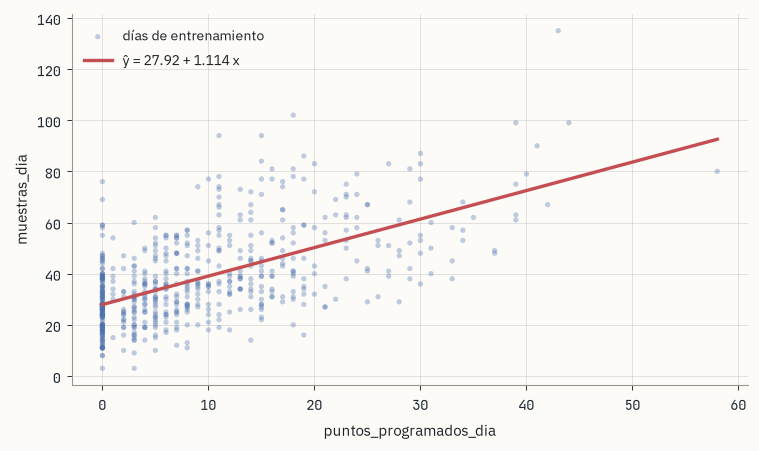

In [14]:
regresion.recta_simple(c).mostrar()

### 9.2 Árbol de regresión con poda por costo-complejidad

Un árbol que crece sin límite termina memorizando el entrenamiento. La poda por costo-complejidad le cobra un
precio `ccp_alpha` a cada hoja y corta las ramas que no reducen el error lo suficiente para pagarlo. Calculamos la
ruta de poda del árbol completo y nos quedamos con el `ccp_alpha` de menor RMSE medio en los bloques así que la
complejidad la decide la validación y no una profundidad que pongamos a mano.

In [15]:
regresion.poda(c).mostrar()

ccp_alpha,Hojas,RMSE medio,Desv. RMSE
0.000,95,17.326,1.558
0.871,48,16.919,1.542
1.290,37,17.190,1.938
1.971,24,16.588,1.882
3.798,12,16.203,2.310
20.522,2,17.003,4.229


### 9.3 Regresión múltiple, KNN, árbol y perceptrón en los mismos bloques

La regresión lineal múltiple predice la carga del día siguiente como una suma ponderada de lo que ya sabemos la
víspera (rezagos, medias móviles, calendario y agenda), con un peso ${\color{#3B64A8}{\beta_j}}$ por variable:

$$\hat y_{t+1} = {\color{#3B64A8}{\beta_0}} + \sum_{j=1}^{p} {\color{#3B64A8}{\beta_j}}\, x_{t,j}$$

KNN promedia la carga de los días más parecidos, el árbol parte los días en grupos con reglas sucesivas y el
perceptrón multicapa es una red neuronal pequeña que combina las variables en capas antes de dar la predicción. Los
cuatro van dentro de una tubería de scikit-learn que imputa, escala y codifica con lo aprendido solo en el tramo
de ajuste de cada bloque. Así se arma la de la regresión múltiple:

In [16]:
from proyecto.modelos import tuberias

tuberia = tuberias.construir_tuberia("regresion", "lineal", c.numericas, c.categoricas)
mostrar(tuberia)   # imputar y escalar las numéricas, codificar las categóricas y ajustar el modelo

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preparar', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transfo

Modelo,Tipo,MAE,RMSE,± RMSE,R²,± R²,Habilidad,Habilidad mínima
base_dia_anterior,referencia,20.165,25.399,3.926,-1.053,0.241,-0.357,-0.381
base_media_5,referencia,14.697,18.757,3.244,-0.111,0.078,0.000,0.000
Dummy (media),referencia,14.603,19.405,4.679,-0.167,0.120,-0.026,-0.106
Lineal simple (puntos_programados_dia),modelo,12.287,15.956,3.959,0.208,0.139,0.157,0.088
Lineal múltiple,modelo,10.446,13.310,2.262,0.440,0.047,0.290,0.283
KNN,modelo,11.498,15.416,3.409,0.259,0.067,0.183,0.140
Árbol podado,modelo,12.694,16.203,2.310,0.151,0.190,0.131,0.040
Perceptrón multicapa,modelo,10.900,14.308,2.807,0.350,0.131,0.238,0.171


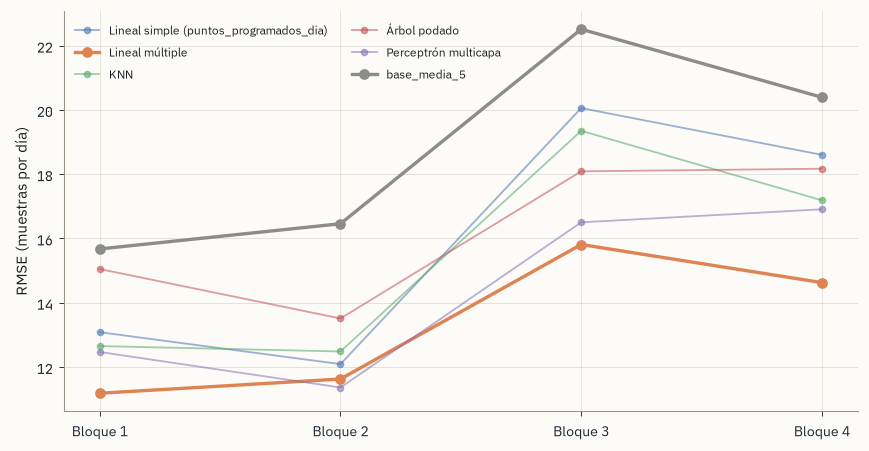

In [17]:
regresion.didactica(c).mostrar()

### 9.4 Qué dicen los coeficientes de la regresión múltiple

Como las variables están estandarizadas, cada coeficiente es el cambio esperado en la carga cuando la variable
sube una desviación estándar y las demás se quedan quietas.

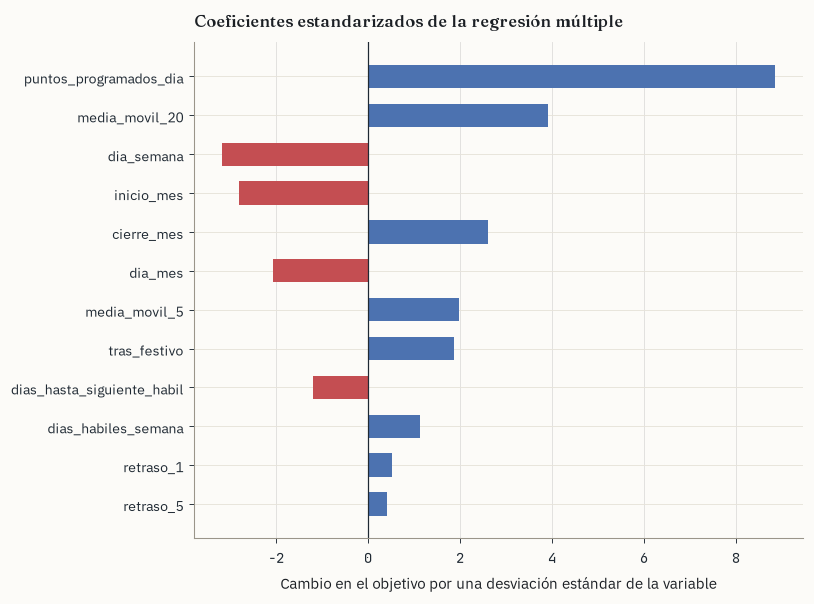

In [18]:
regresion.coeficientes(c).mostrar()

## 10. Nivel 2: Cribado de la tubería con un arreglo L16 de Taguchi

Además del modelo, la tubería decide el escalado, el grupo de variables, si el objetivo va en logaritmo, si se
seleccionan variables y cómo se codifican las discretas. Probar todas las combinaciones exige 4 × 2⁵ = 128
corridas. Un **arreglo ortogonal L16** estima el efecto de cada uno de los seis factores con solo 16, porque cada
nivel de un factor aparece el mismo número de veces frente a cada nivel de los demás. El precio es que algunas
interacciones (cuando el efecto de un factor depende del nivel de otro) quedan mezcladas con los efectos
principales, y la tabla de confusiones dice exactamente cuáles.

El arreglo sale de `arreglos.arreglo_l16()` y antes de usarlo comprobamos que de verdad sea ortogonal:

In [19]:
from proyecto.cribado import arreglos
from proyecto.reporte.html import tabla_html

l16 = arreglos.arreglo_l16()                        # 16 corridas: A con 4 niveles y doce columnas de 2 niveles
ortogonal = arreglos.verificar_ortogonalidad(l16)   # cada par de columnas aparece balanceado
usadas = l16[list(regresion.COLUMNAS_L16.values())].T.set_axis(range(1, 17), axis=1)   # una fila por columna usada
titulo = f"Columnas del L16 que usamos, una por fila (ortogonal: {'Sí' if ortogonal else 'No'})"
mostrar(tabla_html(usadas, titulo, decimales=0, con_indice=True))

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
A,0,0,0,0,1,1,1,1,2,2,2,2,3,3,3,3
c,0,0,1,1,0,0,1,1,0,0,1,1,0,0,1,1
d,0,1,0,1,0,1,0,1,0,1,0,1,0,1,0,1
abd,0,1,0,1,1,0,1,0,1,0,1,0,0,1,0,1
acd,0,1,1,0,0,1,1,0,1,0,0,1,1,0,0,1
bcd,0,1,1,0,1,0,0,1,0,1,1,0,1,0,0,1


A cada corrida le medimos el RMSE en cada bloque y lo resumimos con la razón señal/ruido de Taguchi en la versión
"menor es mejor". Como lleva un menos adelante, una S/N más alta es mejor. Además castiga a la vez un error alto y
un error que cambia mucho entre bloques:

$$\frac{S}{N} = -10\,\log_{10}\Big(\frac{1}{B}\sum_{b=1}^{B}{\color{#B8423F}{\mathrm{RMSE}_b^2}}\Big)$$

In [20]:
regresion.diseno(c).mostrar()

Corrida,modelo,escalado,grupo,objetivo_log,seleccion,codificacion
1,knn,estandar,base,no,ninguna,ordinal
2,knn,estandar,ampliado,sí,8,one_hot
3,knn,minmax,base,no,8,one_hot
4,knn,minmax,ampliado,sí,ninguna,ordinal
5,lineal,estandar,base,sí,ninguna,one_hot
6,lineal,estandar,ampliado,no,8,ordinal
7,lineal,minmax,base,sí,8,ordinal
8,lineal,minmax,ampliado,no,ninguna,one_hot
9,arbol,estandar,base,sí,8,ordinal
10,arbol,estandar,ampliado,no,ninguna,one_hot


Con las 16 corridas calculamos los efectos principales (la S/N media de las corridas que usan cada nivel), la
tabla de respuesta (el delta, o sea la diferencia entre el mejor y el peor nivel de cada factor) y el óptimo que
predice el modelo aditivo. Ese modelo supone que los factores no interactúan y suma lo que aporta cada nivel sobre
la media de las 16 corridas:

$$\widehat{S/N} = {\color{#6B6B6B}{\overline{S/N}}} + \sum_{f}\Big({\color{#2F8A4E}{\overline{S/N}_{f,\,\text{nivel}}}} - {\color{#6B6B6B}{\overline{S/N}}}\Big)$$

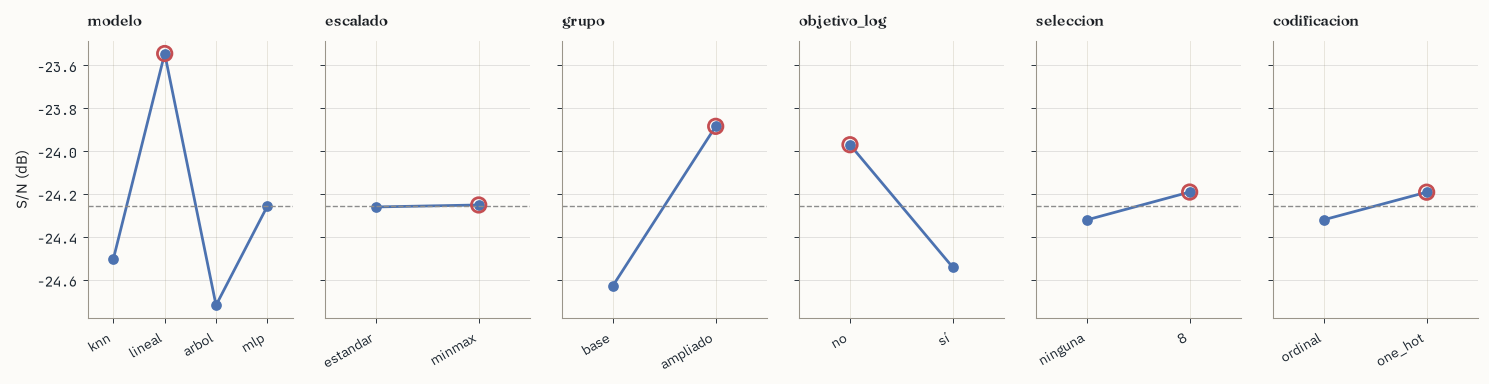

In [21]:
regresion.corridas_l16(c).mostrar()

### Corrida de confirmación y factorial completo

El óptimo predicho es una combinación que el L16 no tiene por qué haber probado así que la corremos aparte y
comparamos la S/N observada con la predicha, con una tolerancia de dos veces el error residual del modelo aditivo.
Después, si el tiempo estimado (el del L16 multiplicado por 128 / 16) no pasa de un minuto, corremos también el
factorial completo para comprobar el atajo de Taguchi.

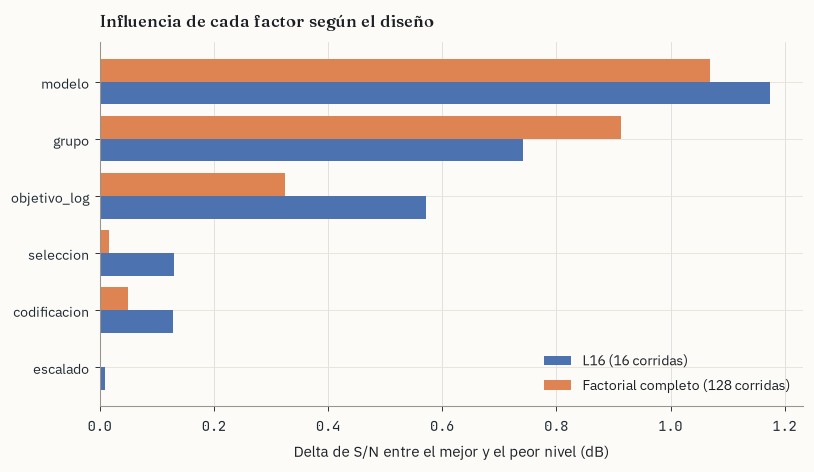

In [22]:
regresion.confirmacion(c).mostrar()

## 11. Nivel 3: Afinamiento de hiperparámetros

Al afinamiento pasa la configuración de mayor S/N observada (la confirmación o la mejor del L16) y, para no
apostarle a una sola familia, la segunda mejor familia de modelos con los demás factores iguales. Las rejillas las
recorremos con `GridSearchCV` sobre los mismos bloques temporales.

In [23]:
regresion.afinamiento(c).mostrar()

### Evaluación única en validación

La regla la fijamos antes de mirar: Gana el menor RMSE de validación y, si la diferencia no llega al uno por
ciento, el modelo más sencillo (lineal, árbol, KNN, perceptrón). Para saber qué tanto se puede mover la habilidad
con otros días usamos un **bootstrap**, que repite el cálculo mil veces sobre días sacados al azar con reemplazo y
se queda con el rango donde cae el 95 % central de los resultados.

In [24]:
regresion.evaluacion_validacion(c).mostrar()

Predictor,MAE,RMSE,R2,Habilidad,RMSE inf.,RMSE sup.,Habilidad inf.,Habilidad sup.
Regresión lineal,11.030,14.591,0.367,0.249,12.229,17.211,0.154,0.343
Perceptrón multicapa,11.730,15.513,0.285,0.201,13.061,18.458,0.102,0.292
base_dia_anterior,20.688,25.768,-0.973,-0.327,,,,
base_media_5,15.355,19.423,-0.121,0.000,,,,
Dummy (media),18.436,24.121,-0.729,-0.242,,,,


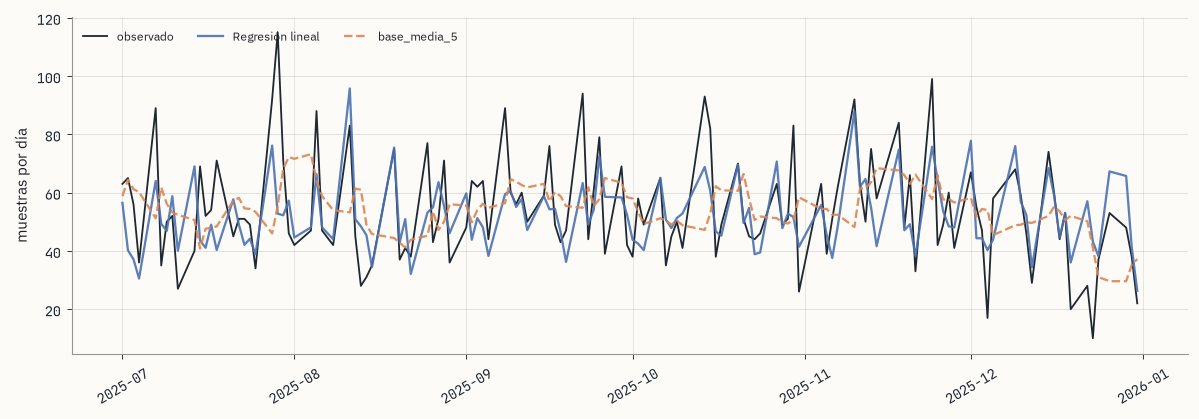

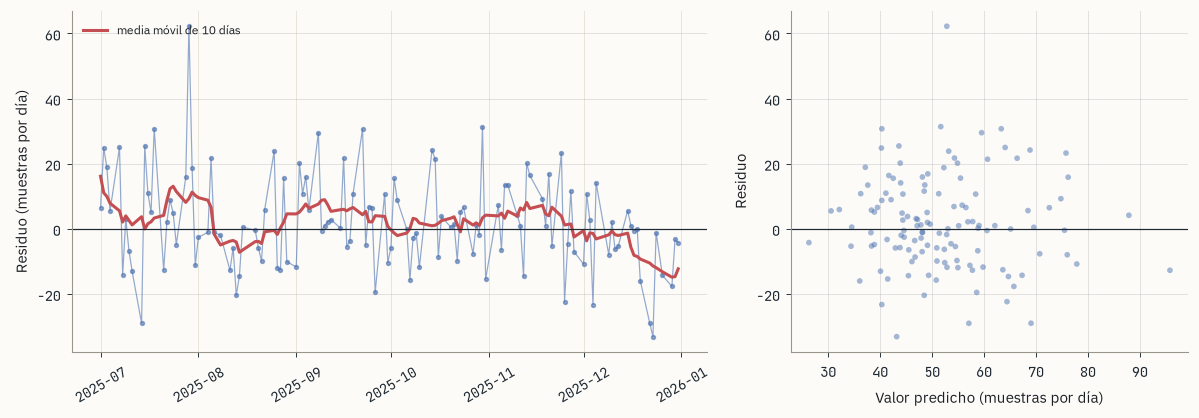

In [25]:
regresion.diagnostico(c).mostrar()

## 12. Congelamiento del modelo

Los hiperparámetros y la configuración quedan fijos y el modelo se reajusta con entrenamiento y validación, porque
los días recientes describen mejor el nivel actual de la serie. La etapa 06 lo evalúa una sola vez en la prueba.

In [26]:
regresion.congelar(c).mostrar()

El modelo congelado queda en disco y desde ahí lo usa la etapa 06. Así se carga y se le piden predicciones. Eso
sí, estos días de validación ya los vio el reajuste así que la tabla solo muestra la llamada y no mide nada: El
error de verdad se mide en la prueba.

In [27]:
import joblib
from proyecto.base import rutas

modelo = joblib.load(rutas.DIR_ARTEFACTOS / "modelos" / "regresion.joblib")   # el que acabamos de congelar
dias = c.validacion.tail(5)
tabla = dias[[c.fecha, c.objetivo]].assign(predicción=modelo.predict(dias[c.numericas + c.categoricas]))
mostrar(tabla_html(tabla, "Modelo congelado: Muestras por día en los últimos días de validación", decimales=1))

fecha,muestras_dia,predicción
2025-12-24,37,36.3
2025-12-26,53,64.6
2025-12-29,48,64.3
2025-12-30,38,40.4
2025-12-31,22,25.3


Antes de cerrar volvimos al L16 para ver qué habría pasado con otra combinación de factores. El panel lo responde
sin volver a correr nada, con lo que guardamos de las 16 corridas. Si la combinación
que se elige está en el L16 se puede comparar lo que predice el modelo aditivo con lo que de verdad se midió.

Panel interactivo: Ejecute la celda con el núcleo en marcha para mover los controles.

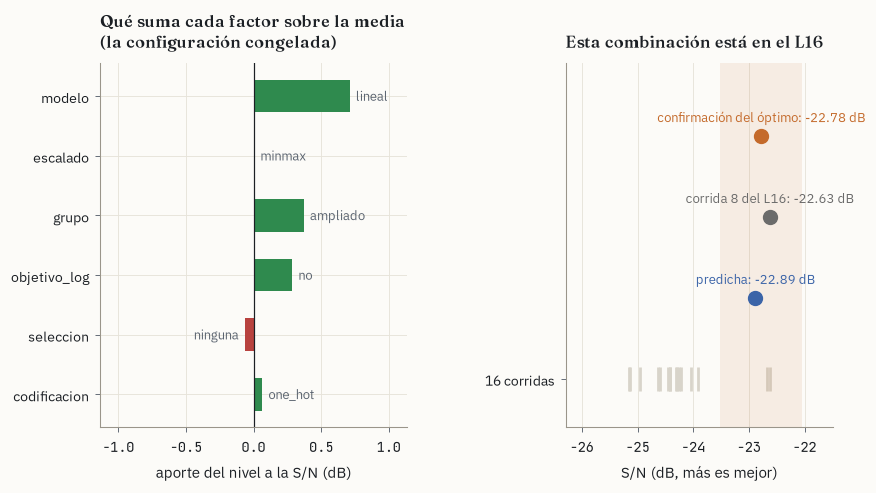

In [28]:
from proyecto.etapas.comun import legible
from proyecto.reporte import interactivo as ui

congelada = {f: legible(v) for f, v in c.configuracion_final.items()}   # niveles de la configuración congelada
mostrar(ui.panel_taguchi(c.taguchi, congelada))

## 13. Qué significa en la operación

Al final traducimos el error a muestras por día y a cuántos días la predicción se aleja más de una tolerancia
práctica, que fijamos en el 20 % de la carga diaria media de validación.

In [29]:
regresion.operacion(c).mostrar()

In [30]:
regresion.terminar(c)

← Anterior: [Etapa 02: Base real](02_base_real.ipynb)<br>[Notebook completo](Proyecto_Final.ipynb)<br>Siguiente: [Etapa 04: Clasificación y Bayes](04_clasificacion_bayes.ipynb) →